# ReXTrust — End-to-End Pipeline

Implements the architecture from `TEAM_95_PR2.pdf` (slide 5):

```
Chest X-ray Input ─► Image Quality Assessment ─┬─ low quality ─► Image Enhancement (Attention U-Net + CLAHE) ─┐
                                               └─ acceptable ──► Skip Enhancement (passed unchanged) ────────┤
                                                                                                             ▼  enhanced image
                     ┌──────────────────────────────────────────────────────────┬──────────────────────────────┘
                     ▼                                                          ▼
        Disease Detection (Multi-Label, DenseNet121)              Vision-Language Model (MediVLM)
                     ▼                                                          ▼
        Explainability — Score-CAM (Heatmap A/B/C)                RadCheck — Report Grounding (AMG-RAG)
                     └───────────────────────► Structured Diagnostic Output ◄───┘
```

Entry point: **`run_pipeline(image_path)`**. Each stage is a separate function: `enhance_image`, `detect_disease`,
`score_cam`, `generate_report`.

### Score-CAM — Explainability Notes

Score-CAM generates one heatmap per disease label by masking penultimate convolutional feature maps
and scoring each channel contribution. Channel count is capped at 1024 on GPU and 256 on CPU.
The heatmap is overlaid on the enhanced image using the jet colormap.


### MediVLM — Report Generation Integration

The model checkpoint (mimic_sample.ckpt) is cloned from the MediVLM repository on first run.
Inference feeds the enhanced X-ray image and a short prompt; the model returns a structured
radiology report. Report quality depends on the disease-detection labels passed as context.


### Disease Detection — Model Comparison Notes

All four detectors (**CNN baseline**, **CNN matched**, **Hybrid CNN-Transformer**, **CheXGCN**) run in
parallel so their confidence scores can be compared side-by-side on every input image.
The primary detector selected in pp.py drives the Score-CAM heatmap; all four scores appear in
the result panel.


## Setup

In [1]:
import os, sys, re, json, shutil, subprocess, contextlib, io, textwrap, time, warnings
from pathlib import Path

import numpy as np
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from torchvision import models

warnings.filterwarnings("ignore")
torch.set_grad_enabled(False)  # inference only

ROOT = Path.cwd()
MODELS = ROOT / "Models"
# README asks to rename the file without the space; accept either name
ENHANCER_WEIGHTS = next(p for p in [MODELS / "Enhancement" / "unet_attention_v4.pt",
                                    MODELS / "Enhancement" / "unet_attention_v4 .pt"] if p.exists())
CNN_WEIGHTS = MODELS / "Disease Detection" / "best_cnn.pth"
MEDIVLM_CKPT = MODELS / "Report" / "mimic_sample.ckpt"
MEDIVLM_REPO = MODELS / "Report" / "MediVLM"
MEDIVLM_URL, MEDIVLM_COMMIT = "https://github.com/sonai-commits/MediVLM.git", "f5a6e1dd0c4139f9fbd3cd075545a3b22a1a14b8"

SAMPLE_IMAGES = ["1.jpg"]
RESULTS_DIR = ROOT / "results"  # one sub-folder per image + summary.csv

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Disease detection (rextrust-stage2-scaled_6k.ipynb, Technique 1 "cnn" -> best_cnn.pth)
DISEASES = ["Cardiomegaly", "Edema", "Pleural Effusion"]
THRESHOLDS = [0.245, 0.404, 0.507]          # F1-optimal, tuned on the validation split
CNN_SIZE = 224
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

# Image quality gate (Enhancement README §5)
BRISQUE_THRESHOLD, ENTROPY_THRESHOLD = 5.0, 7.95

# Score-CAM: all 1024 denseblock4 channels on GPU; on CPU keep the 256 highest-variance
# channels (~4x faster, ~1 min/image) -- set to None to always use all channels.
SCORECAM_MAX_CHANNELS = None if DEVICE.type == "cuda" else 256

NUM_BEAMS = 4  # MediVLM beam search
REPORT_MAX_TOKENS = 150  # the checkpoint's own limit (77) cuts the first report off mid-sentence

# API keys: environment first, then the project's .env file (never hard-coded here)
if (ROOT / ".env").exists():
    from decouple import Config, RepositoryEnv
    _env = Config(RepositoryEnv(str(ROOT / ".env")))
    for _k in ("GOOGLE_API_KEY", "pubmed_api"):
        if not os.environ.get(_k) and _env(_k, default=""):
            os.environ[_k] = _env(_k)

print(f"Device: {DEVICE} | torch {torch.__version__}")
print(f"GOOGLE_API_KEY configured: {bool(os.environ.get('GOOGLE_API_KEY'))}")

Device: cpu | torch 2.14.0+cpu
GOOGLE_API_KEY configured: True


## Chest X-ray Input

Accepts JPEG/PNG (any size, 8/16-bit, gray or colour) and DICOM (`.dcm`, needs `pydicom`). All are converted to
grayscale `uint8`, which is what the enhancement module expects.

In [2]:
def load_xray(path) -> np.ndarray:
    path = Path(path)
    if path.suffix.lower() == ".dcm":
        import pydicom
        img = pydicom.dcmread(str(path)).pixel_array.astype(np.float32)
    else:
        img = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
        if img is None:
            raise FileNotFoundError(path)
        if img.ndim == 3:
            img = cv2.cvtColor(img, cv2.COLOR_BGRA2GRAY if img.shape[2] == 4 else cv2.COLOR_BGR2GRAY)
    if img.dtype != np.uint8:  # 16-bit PNG / DICOM -> min-max to uint8
        img = img.astype(np.float32)
        img = (img - img.min()) / max(float(img.max() - img.min()), 1e-6) * 255
        img = img.astype(np.uint8)
    return img

## Image Quality Assessment

Rule from the Enhancement README: `needs_enhancement = BRISQUE > 5.0 or entropy < 7.95`, computed on the
256×256 copy. BRISQUE uses `piq` if it is installed; otherwise only entropy is used.

In [3]:
try:
    import piq
except ImportError:
    piq = None

def assess_quality(gray256: np.ndarray) -> dict:
    hist = np.bincount(gray256.ravel(), minlength=256) / gray256.size
    hist = hist[hist > 0]
    entropy = float(-(hist * np.log2(hist)).sum())
    brisque = float("nan")
    if piq is not None:
        brisque = float(piq.brisque(torch.from_numpy(gray256).float().div(255)[None, None], data_range=1.0))
    sharpness = float(cv2.Laplacian(gray256, cv2.CV_64F).var())

    reasons = []
    if not np.isnan(brisque) and brisque > BRISQUE_THRESHOLD:
        reasons.append(f"BRISQUE {brisque:.2f} > {BRISQUE_THRESHOLD}")
    if entropy < ENTROPY_THRESHOLD:
        reasons.append(f"entropy {entropy:.2f} < {ENTROPY_THRESHOLD}")
    return {"brisque": round(brisque, 2), "entropy": round(entropy, 2), "sharpness": round(sharpness, 1),
            "needs_enhancement": bool(reasons), "reason": "; ".join(reasons) or "passes quality gate"}

## Image Enhancement — Attention U-Net + CLAHE

`unet_attention_v4.py` is not in the project folder, so the network is rebuilt here from the checkpoint's 247
state-dict keys: ResBlock encoder/decoder, CBAM at the bottleneck, and attention gates on every skip connection
(8.24 M parameters). The load is **strict**.

* Model input is `[1, 3, 256, 256]` in [0, 1] (grayscale copied to 3 channels).
* The output is averaged over the 3 channels, scaled to `uint8`, then CLAHE(2.0, 8×8) is applied.
* **Skip Enhancement:** if the quality gate passes, the resized original is passed through unchanged.

In [4]:
class ResBlock(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout))
        self.shortcut = nn.Sequential(nn.Conv2d(cin, cout, 1, bias=False), nn.BatchNorm2d(cout))
        self.act = nn.ReLU(inplace=True)

    def forward(self, x):
        return self.act(self.conv(x) + self.shortcut(x))


class ChannelAttention(nn.Module):
    def __init__(self, c, r=16):
        super().__init__()
        self.mlp = nn.Sequential(nn.Flatten(), nn.Linear(c, c // r, bias=False), nn.ReLU(inplace=True),
                                 nn.Linear(c // r, c, bias=False))

    def forward(self, x):
        a = self.mlp(F.adaptive_avg_pool2d(x, 1)) + self.mlp(F.adaptive_max_pool2d(x, 1))
        return x * torch.sigmoid(a)[:, :, None, None]


class SpatialAttention(nn.Module):
    def __init__(self, k=7):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, k, padding=k // 2, bias=False)

    def forward(self, x):
        return x * torch.sigmoid(self.conv(torch.cat([x.mean(1, keepdim=True), x.amax(1, keepdim=True)], 1)))


class CBAM(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.ca, self.sa = ChannelAttention(c), SpatialAttention()

    def forward(self, x):
        return self.sa(self.ca(x))


class AttentionGate(nn.Module):
    """g = upsampled decoder feature, x = encoder skip; returns gated skip + mask."""
    def __init__(self, cg, cx, ci):
        super().__init__()
        self.W_g = nn.Sequential(nn.Conv2d(cg, ci, 1, bias=False), nn.BatchNorm2d(ci))
        self.W_x = nn.Sequential(nn.Conv2d(cx, ci, 1, bias=False), nn.BatchNorm2d(ci))
        self.psi = nn.Sequential(nn.Conv2d(ci, 1, 1, bias=False), nn.BatchNorm2d(1), nn.Sigmoid())
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        a = self.psi(self.relu(self.W_g(g) + self.W_x(x)))
        return x * a, a


class AttnUNet(nn.Module):
    def __init__(self, cin=3, cout=3, f=(32, 64, 128, 256, 512)):
        super().__init__()
        self.enc1, self.enc2, self.enc3, self.enc4 = (ResBlock(cin, f[0]), ResBlock(f[0], f[1]),
                                                      ResBlock(f[1], f[2]), ResBlock(f[2], f[3]))
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = ResBlock(f[3], f[4])
        self.cbam = CBAM(f[4])
        self.up4, self.up3, self.up2, self.up1 = [nn.ConvTranspose2d(f[i + 1], f[i], 2, stride=2) for i in (3, 2, 1, 0)]
        self.ag4, self.ag3, self.ag2, self.ag1 = [AttentionGate(f[i], f[i], f[i] // 2) for i in (3, 2, 1, 0)]
        self.dec4, self.dec3, self.dec2, self.dec1 = [ResBlock(f[i] * 2, f[i]) for i in (3, 2, 1, 0)]
        self.head = nn.Sequential(nn.Conv2d(f[0], cout, 1), nn.Sigmoid())

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        d = self.cbam(self.bottleneck(self.pool(e4)))
        for i, skip in ((4, e4), (3, e3), (2, e2), (1, e1)):
            g = getattr(self, f"up{i}")(d)
            gated, _ = getattr(self, f"ag{i}")(g, skip)
            d = getattr(self, f"dec{i}")(torch.cat([g, gated], 1))
        return self.head(d)


enhancer = AttnUNet()
enhancer.load_state_dict(torch.load(ENHANCER_WEIGHTS, map_location="cpu"), strict=True)
enhancer.to(DEVICE).eval()
CLAHE = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
print(f"Attention U-Net loaded: {sum(p.numel() for p in enhancer.parameters()) / 1e6:.2f} M params")


def enhance_image(image_path, force: bool = False) -> dict:
    """Quality gate -> (Attention U-Net + CLAHE | skip). Returns the 256x256 uint8 enhanced image + metadata."""
    original = load_xray(image_path)
    resized = cv2.resize(original, (256, 256), interpolation=cv2.INTER_AREA)  # aspect not preserved (as trained)
    q_before = assess_quality(resized)

    if q_before["needs_enhancement"] or force:
        x = torch.from_numpy(resized).float().div(255)[None, None].repeat(1, 3, 1, 1).to(DEVICE)
        unet_out = (enhancer(x).mean(1)[0].cpu().numpy() * 255).clip(0, 255).astype(np.uint8)
        enhanced, method = CLAHE.apply(unet_out), "attn_unet_clahe"
    else:
        enhanced, method = resized.copy(), "passthrough"

    return {"original": original, "original_resized": resized, "enhanced": enhanced,
            "was_enhanced": method != "passthrough", "method": method,
            "quality_before": q_before, "quality_after": assess_quality(enhanced)}

Attention U-Net loaded: 8.24 M params


## Disease Detection (Multi-Label)

`best_cnn.pth` is Technique 1 from `rextrust-stage2-scaled_6k.ipynb`: DenseNet121 features → ReLU → global average
pooling → Linear(1024, 3), saved as a plain state dict. Preprocessing matches training: 224×224 RGB with ImageNet
normalization. Each disease is positive when its sigmoid probability exceeds that disease's validation-tuned threshold.

> Note: this CNN was trained on **raw** CheXpert images. Here it receives the enhanced image (as the architecture
> specifies), which differs from its training data.

In [5]:
class CNNClassifier(nn.Module):
    def __init__(self, num_classes=3, dropout=0.0):
        super().__init__()
        self.backbone = models.densenet121(weights=None).features
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(1024, num_classes)

    def forward(self, x):
        feat = F.relu(self.backbone(x))
        return self.classifier(self.dropout(self.pool(feat).flatten(1)))


cnn = CNNClassifier(num_classes=len(DISEASES))
cnn.load_state_dict(torch.load(CNN_WEIGHTS, map_location="cpu"), strict=True)
cnn.to(DEVICE).eval()
_MEAN = torch.tensor(IMAGENET_MEAN, device=DEVICE)[:, None, None]
_STD = torch.tensor(IMAGENET_STD, device=DEVICE)[:, None, None]


def cnn_input(enhanced: np.ndarray) -> torch.Tensor:
    rgb = cv2.cvtColor(cv2.resize(enhanced, (CNN_SIZE, CNN_SIZE)), cv2.COLOR_GRAY2RGB)
    x = torch.from_numpy(rgb).to(DEVICE).permute(2, 0, 1).float().div(255)
    return ((x - _MEAN) / _STD)[None]


def detect_disease(enhanced: np.ndarray) -> dict:
    probs = torch.sigmoid(cnn(cnn_input(enhanced)))[0].cpu().numpy()
    positive = [d for d, p, t in zip(DISEASES, probs, THRESHOLDS) if p > t]
    top = int(probs.argmax())
    return {"probabilities": {d: float(p) for d, p in zip(DISEASES, probs)},
            "thresholds": dict(zip(DISEASES, THRESHOLDS)),
            "positive": positive,
            "predicted_class": ", ".join(positive) if positive else "No finding (of the 3 target diseases)",
            "top_disease": DISEASES[top], "top_confidence": float(probs[top])}

## Explainability — Score-CAM

This builds one heatmap per disease (Heatmap A/B/C), each from that disease's own class score, on `denseblock4`
as in the detection notebook. It follows pytorch-grad-cam's `ScoreCAM`:

1. Upsample each activation map and min-max scale it to [0, 1].
2. Mask the input with it and score the masked image with the class logit.
3. Weight the maps by the softmax of those scores over channels, sum, and apply ReLU.

One sweep over the channels scores all 3 diseases at once.

In [6]:
def score_cam(enhanced: np.ndarray, max_channels=SCORECAM_MAX_CHANNELS, batch_size=32) -> dict:
    x = cnn_input(enhanced)
    acts = {}
    hook = cnn.backbone.denseblock4.register_forward_hook(lambda m, i, o: acts.__setitem__("A", o))
    try:
        cnn(x)
    finally:
        hook.remove()
    A = acts["A"][0]                                                    # (1024, 7, 7)
    if max_channels and max_channels < A.shape[0]:
        A = A[A.flatten(1).var(1).topk(max_channels).indices]
    up = F.interpolate(A[None], size=x.shape[-2:], mode="bilinear", align_corners=False)[0]
    lo, hi = up.flatten(1).min(1)[0][:, None, None], up.flatten(1).max(1)[0][:, None, None]
    masks = (up - lo) / (hi - lo + 1e-8)

    logits = torch.cat([cnn(x * masks[i:i + batch_size, None]) for i in range(0, len(masks), batch_size)])  # (K, 3)
    weights = torch.softmax(logits, dim=0)
    cams = F.relu(torch.einsum("kc,khw->chw", weights, up))
    cams = cams - cams.flatten(1).min(1)[0][:, None, None]
    cams = cams / (cams.flatten(1).max(1)[0][:, None, None] + 1e-7)
    return {d: cams[i].cpu().numpy() for i, d in enumerate(DISEASES)}

## Vision-Language Model — MediVLM

This uses the same code and calls as `Models/Report/MediVLM_AMG_RAG_Pipeline.ipynb`: the `MediVLM` class from the
public repo, `build_image_transform(224, train=False)`, and `model.generate(img, num_beams=4)`. Differences from
that notebook:

* The repo is cloned once into `Models/Report/MediVLM`, pinned to a fixed commit. The repo ships stale `.pyc`
  files, which are removed.
* The model config is read from the checkpoint itself (`ckpt["config"]`) instead of a guessed YAML file.
* `mimic_sample.ckpt` contains **every** weight (detector, CLIP-L/14, ClinicalBERT, GPT-2). The HF sub-models are
  therefore built from their configs only, which avoids downloading ~2.5 GB of weights. The checkpoint is
  memory-mapped, so the optimizer state is never loaded.
* The load is **strict**. transformers ≥ 5 removed the `vision_model.` level from `CLIPVisionModel` keys, so those
  checkpoint keys are remapped. With the original `strict=False` load, CLIP would silently stay randomly initialized.

In [7]:
def _ensure_medivlm_repo():
    if not (MEDIVLM_REPO / "medivlm").exists():
        subprocess.run(["git", "clone", "-q", MEDIVLM_URL, str(MEDIVLM_REPO)], check=True)
        subprocess.run(["git", "-C", str(MEDIVLM_REPO), "checkout", "-q", MEDIVLM_COMMIT], check=True)
    for d in MEDIVLM_REPO.rglob("__pycache__"):
        shutil.rmtree(d)
    if str(MEDIVLM_REPO) not in sys.path:
        sys.path.insert(0, str(MEDIVLM_REPO))


def load_medivlm():
    _ensure_medivlm_repo()
    from unittest import mock
    from transformers import AutoConfig, AutoModel, CLIPVisionConfig, CLIPVisionModel, GPT2LMHeadModel
    from medivlm.models.medivlm import MediVLM
    from medivlm.models import detector as detector_module
    from medivlm.utils.config import MediVLMConfig, _update_dataclass
    from medivlm.data.transforms import build_image_transform

    ckpt = torch.load(MEDIVLM_CKPT, map_location="cpu", mmap=True, weights_only=False)
    cfg = _update_dataclass(MediVLMConfig(), ckpt["config"])

    patches = [
        mock.patch.object(CLIPVisionModel, "from_pretrained",
                          classmethod(lambda cls, name, *a, **k: cls._from_config(CLIPVisionConfig.from_pretrained(name)))),
        mock.patch.object(GPT2LMHeadModel, "from_pretrained",
                          classmethod(lambda cls, name, *a, **k: cls._from_config(AutoConfig.from_pretrained(name)))),
        mock.patch.object(AutoModel, "from_pretrained",
                          lambda name, *a, **k: AutoModel.from_config(AutoConfig.from_pretrained(name))),
        mock.patch.object(detector_module, "resnet34", lambda weights=None: models.resnet34(weights=None)),
    ]
    with contextlib.ExitStack() as stack:
        for p in patches:
            stack.enter_context(p)
        model = MediVLM(cfg)

    expected = model.state_dict().keys()
    state = {}
    for k, v in ckpt["model"].items():
        k2 = k.replace("image_encoder.vision.vision_model.", "image_encoder.vision.")
        state[k if k in expected else k2] = v
    model.load_state_dict(state, strict=True)
    model.to(DEVICE).eval()
    return model, build_image_transform(cfg.image_encoder.image_size, train=False), ckpt.get("metrics", {})


t0 = time.time()
medivlm, medivlm_transform, medivlm_metrics = load_medivlm()
print(f"MediVLM loaded in {time.time() - t0:.0f}s | checkpoint val metrics: "
      + ", ".join(f"{k}={v:.3f}" for k, v in medivlm_metrics.items()))

MediVLM loaded in 26s | checkpoint val metrics: BLEU-1=0.375, BLEU-2=0.251, BLEU-3=0.182, BLEU-4=0.132, METEOR=0.379, ROUGE-L=0.262


## RadCheck — Report Grounding

This is the 5-step AMG-RAG hallucination detector, copied **unchanged** from the report notebook (Section 7).
The only changes:
* The API key is read from the environment or `.env` instead of `getpass`.
* Each Gemma call has `timeout=120, max_retries=2`, so a rate-limited API fails over to "UNVERIFIED" instead of
  hanging the pipeline.

In [8]:
"""
AMG-RAG: Clinical Report Hallucination Detection System
5-Step Pipeline:
  1. Report Ingestion & Extraction
  2. LLM Baseline Check (typical / atypical)
  3. PubMed Grounding — only if atypical
  4. MKG Contradiction Engine
  5. Final Verdict: Hallucinated / Not Hallucinated with confidence score
"""

import time
import os
import json
import re
from typing import List, Dict, Optional, Any
from dataclasses import dataclass, field
import networkx as nx
from langchain_google_genai import ChatGoogleGenerativeAI  # pyright: ignore[reportMissingImports]
from langchain_core.prompts import PromptTemplate  # pyright: ignore[reportMissingImports]
from langchain_classic.output_parsers import ResponseSchema, StructuredOutputParser  # pyright: ignore[reportMissingImports]
import requests
from xml.etree import ElementTree as ET
# Configuration (keys come from the environment / .env, loaded in the Setup cell)
GOOGLE_API_KEY = os.environ.get('GOOGLE_API_KEY')
PUBMED_API_KEY = os.environ.get('pubmed_api') or None


# ──────────────────────────────────────────────
# Data Classes
# ──────────────────────────────────────────────
@dataclass
class MedicalEntity:
    """Represents a medical entity in the knowledge graph"""
    name: str
    description: str
    entity_type: str
    confidence: float = 1.0
    sources: List[str] = field(default_factory=list)

@dataclass
class MedicalRelation:
    """Represents a relationship between medical entities"""
    source: str
    target: str
    relation_type: str
    confidence: float
    evidence: str
    sources: List[str] = field(default_factory=list)


# ──────────────────────────────────────────────
# Medical Knowledge Graph
# ──────────────────────────────────────────────
class MedicalKnowledgeGraph:
    """Dynamic Medical Knowledge Graph with confidence scoring"""

    def __init__(self):
        self.graph = nx.DiGraph()
        self.entities = {}
        self.relations = []

    def add_entity(self, entity: MedicalEntity):
        self.entities[entity.name] = entity
        self.graph.add_node(
            entity.name,
            description=entity.description,
            entity_type=entity.entity_type,
            confidence=entity.confidence,
            sources=entity.sources,
        )

    def add_relation(self, relation: MedicalRelation):
        self.relations.append(relation)
        self.graph.add_edge(
            relation.source,
            relation.target,
            relation_type=relation.relation_type,
            confidence=relation.confidence,
            evidence=relation.evidence,
            sources=relation.sources,
        )

    def get_connected_nodes(self, node_name: str, confidence_threshold: float = 0.0):
        connected = []
        if node_name in self.graph:
            for neighbor in self.graph.neighbors(node_name):
                edge_data = self.graph[node_name][neighbor]
                if edge_data.get("confidence", 0) >= confidence_threshold:
                    connected.append(
                        {
                            "node": neighbor,
                            "relation": edge_data.get("relation_type"),
                            "confidence": edge_data.get("confidence"),
                            "evidence": edge_data.get("evidence"),
                        }
                    )
        return connected


# ──────────────────────────────────────────────
# PubMed Searcher
# ──────────────────────────────────────────────
class PubMedSearcher:
    """PubMed API wrapper for medical literature search"""

    def __init__(self, api_key: Optional[str] = None):
        self.api_key = api_key
        self.base_url = "https://eutils.ncbi.nlm.nih.gov/entrez/eutils"

    def search(self, query: str, max_results: int = 3) -> List[str]:
        time.sleep(0.5)
        search_url = f"{self.base_url}/esearch.fcgi"
        search_params = {
            "db": "pubmed",
            "term": query,
            "retmode": "xml",
            "retmax": max_results,
        }
        if self.api_key:
            search_params["api_key"] = self.api_key

        try:
            response = requests.get(search_url, params=search_params, timeout=30)
            if response.status_code != 200:
                return []
            if not response.text.strip().startswith("<"):
                return []

            root = ET.fromstring(response.text)
            pmids = [id_elem.text for id_elem in root.findall(".//Id")]
            if not pmids:
                return []

            time.sleep(0.5)
            fetch_url = f"{self.base_url}/efetch.fcgi"
            fetch_params = {
                "db": "pubmed",
                "id": ",".join(pmids),
                "retmode": "text",
                "rettype": "abstract",
            }
            if self.api_key:
                fetch_params["api_key"] = self.api_key

            response = requests.get(fetch_url, params=fetch_params, timeout=30)
            if response.status_code != 200:
                return []

            articles = response.text.split("\n\n")
            abstracts = []
            for article in articles:
                lines = article.split("\n")
                abstract_lines = [
                    line
                    for line in lines
                    if line.strip()
                    and not any(
                        skip in line.lower()
                        for skip in ["author", "doi", "pmid", "copyright"]
                    )
                ]
                if abstract_lines:
                    abstracts.append(" ".join(abstract_lines))
            return abstracts

        except Exception as e:
            print(f"  PubMed search error: {e}")
            return []


# ──────────────────────────────────────────────
# Helpers
# ──────────────────────────────────────────────
def _align_lists(*lists, fill="N/A"):
    """Force all extracted arrays to the same length so index-based
    alignment (findings[i] <-> anatomical_targets[i] <-> ...) can't
    silently drift when the LLM returns mismatched array lengths."""
    max_len = max((len(l) for l in lists), default=0)
    return [list(l) + [fill] * (max_len - len(l)) for l in lists]


def _short_error(e) -> str:
    """One readable line instead of the API's full JSON error payload."""
    s = str(e)
    if "RESOURCE_EXHAUSTED" in s or " 429" in s:
        m = re.search(r"retry in ((?:\d+h)?(?:\d+m)?)", s)
        return "Gemini API quota exhausted" + (f", resets in {m.group(1)}" if m and m.group(1) else "")
    if "DEADLINE_EXCEEDED" in s or " 504" in s:
        return "Gemini API timed out (504)"
    if "API key" in s or "PERMISSION_DENIED" in s or " 403" in s:
        return "Gemini API key rejected"
    return s.strip().splitlines()[0][:160] if s.strip() else type(e).__name__


def _as_list(value):
    """LLM fields sometimes come back as a bare string/number (or None) instead of a list."""
    if value is None:
        return []
    if isinstance(value, (list, tuple)):
        return list(value)
    return [value]


def _as_str_list(value):
    return [v if isinstance(v, str) else json.dumps(v) if isinstance(v, (dict, list)) else str(v)
            for v in _as_list(value)]


def _as_float(value, default=0.5):
    try:
        return min(1.0, max(0.0, float(value)))
    except (TypeError, ValueError):
        return default


def _normalize_contradiction_pairs(raw_pairs, num_findings):
    """The LLM is asked for pairs like [0, 2] but the scoring logic needs
    a list of index-lists, e.g. [[0, 2], [1, 3]]. Handle both shapes and
    drop anything that doesn't parse as a valid pair of in-range indices."""
    normalized = []
    if not raw_pairs:
        return normalized

    # Case: flat list like [0, 2, 1, 3] -> treat as consecutive pairs
    if raw_pairs and all(isinstance(x, (int, float)) for x in raw_pairs):
        it = iter(raw_pairs)
        raw_pairs = [[a, b] for a, b in zip(it, it)]

    for pair in raw_pairs:
        if isinstance(pair, (list, tuple)) and len(pair) >= 2:
            try:
                a, b = int(pair[0]), int(pair[1])
            except (TypeError, ValueError):
                continue
            if 0 <= a < num_findings and 0 <= b < num_findings:
                normalized.append([a, b])
    return normalized


# ──────────────────────────────────────────────
# Main System
# ──────────────────────────────────────────────
class AMG_RAG_ReportSystem:
    """AMG-RAG system for Clinical Report Hallucination Detection"""

    def __init__(self, google_api_key: str = None):
        if google_api_key:
            # gemini-2.5-flash answers in ~2 s; gemma-4-31b-it kept hitting 504 timeouts (~10 min per report).
            # Each Gemini model has its own free-tier quota (gemini-2.5-flash: 20 requests/day), so when one is
            # exhausted or times out the next model in the chain answers instead.
            # Override with RADCHECK_MODEL and RADCHECK_FALLBACK_MODELS (comma-separated).
            self.models = [os.environ.get("RADCHECK_MODEL", "gemini-2.5-flash")] + [
                m.strip() for m in os.environ.get("RADCHECK_FALLBACK_MODELS",
                                                  "gemini-3.5-flash,gemini-2.5-flash-lite").split(",") if m.strip()]
            llms = [ChatGoogleGenerativeAI(
                model=m,
                temperature=0.0,
                timeout=120,      # added: fail instead of hanging
                max_retries=1,    # added
                google_api_key=google_api_key,
            ) for m in self.models]
            self.llm = llms[0].with_fallbacks(llms[1:]) if len(llms) > 1 else llms[0]
        else:
            raise ValueError("Google API key is required.")

        self.kg = MedicalKnowledgeGraph()
        self.pubmed = PubMedSearcher(api_key=PUBMED_API_KEY)
        self._setup_chains()

    # ──────────────────────────────────────────
    # Chain Setup
    # ──────────────────────────────────────────
    def _setup_chains(self):
        """Setup LLM chains for the 5-step report pipeline"""

        # ── Step 1 chain: Report Ingestion & Extraction ──
        finding_schemas = [
            ResponseSchema(
                name="findings",
                description="List of clinical claims/findings parsed from the report",
                type="array",
            ),
            ResponseSchema(
                name="anatomical_targets",
                description="The anatomical structures associated with each finding",
                type="array",
            ),
            ResponseSchema(
                name="clinical_status",
                description="Clinical observation status for each finding (e.g. 'normal', 'abnormal', 'clear')",
                type="array",
            ),
        ]
        finding_parser = StructuredOutputParser.from_response_schemas(finding_schemas)

        self.finding_extractor = (
            PromptTemplate(
                template="""Extract all individual medical findings/claims and associated anatomical structures from this clinical report.

            Report: {report}

            For each finding/claim, provide:
            1. The finding statement
            2. The anatomical target structure
            3. The clinical status (e.g. normal, abnormal, clear, consolidated, etc.)

            IMPORTANT: The three output arrays (findings, anatomical_targets, clinical_status)
            MUST all be the same length and index-aligned — element i of each array must
            describe the same finding.

            Return in JSON format:
            {format_instructions}""",
                input_variables=["report"],
                partial_variables={
                    "format_instructions": finding_parser.get_format_instructions()
                },
            )
            | self.llm
            | finding_parser
        )

        # ── Step 2 chain: LLM Baseline Check ──
        baseline_schemas = [
            ResponseSchema(
                name="classifications",
                description="For each finding: 'typical' if a standard/expected clinical observation, 'atypical' if unusual, rare, or potentially suspicious",
                type="array",
            ),
            ResponseSchema(
                name="reasoning",
                description="Brief reasoning for each classification",
                type="array",
            ),
        ]
        baseline_parser = StructuredOutputParser.from_response_schemas(
            baseline_schemas
        )

        self.baseline_checker = (
            PromptTemplate(
                template="""You are a clinical radiology expert. For each finding below, classify it as either 'typical' or 'atypical'.

            DEFINITIONS:
            - 'typical': A standard, commonly seen clinical observation (e.g. 'heart is normal size', 'lungs are clear', 'no pleural effusion', 'mild cardiomegaly', 'pneumothorax').
            - 'atypical': A finding that is extremely rare, highly unusual, internally contradictory, physiologically impossible, or highly suspicious. This includes:
              a) Extremely rare congenital conditions (e.g. 'dextrocardia', 'situs inversus')
              b) Internally contradictory statements (e.g. 'normal size with severe cardiomegaly', 'clear lungs with massive consolidation')
              c) Impossible whole-organ counts (e.g. 'patient has 3 lungs')
              d) Impossible or incorrect counts of normal anatomical SUBSTRUCTURES — lobes, chambers,
                 valves, vessels, etc. — relative to known human anatomy. For example: the left lung
                 normally has 2 lobes and the right lung has 3 lobes, so "three lobes in the left lung"
                 is atypical/anatomically impossible. The heart normally has 4 chambers, so "five
                 chambers" would be atypical. Apply this same substructure-count check to any
                 anatomical structure mentioned, not just the examples given here.

            NOTE: Common abnormal findings (e.g. pleural effusion, tumors) are still 'typical'. Extremely rare congenital conditions, impossible/contradictory statements, and impossible substructure counts MUST be flagged as 'atypical'.

            Findings to classify:
            {findings_list}

            IMPORTANT: Return exactly one classification and one reasoning entry per finding listed above, in the same order.

            Return in JSON format:
            {format_instructions}""",
                input_variables=["findings_list"],
                partial_variables={
                    "format_instructions": baseline_parser.get_format_instructions()
                },
            )
            | self.llm
            | baseline_parser
        )

        # ── Step 4 chain: MKG Contradiction Engine ──
        contradiction_schemas = [
            ResponseSchema(
                name="contradictions",
                description="List of contradiction descriptions found between findings. Empty list if none found.",
                type="array",
            ),
            ResponseSchema(
                name="contradiction_pairs",
                description="List of [index_a, index_b] pairs indicating which findings are involved in each contradiction. For a contradiction between two different findings, use their two distinct indices, e.g. [0, 2]. For a contradiction involving only ONE finding (self-contradictory statement, or physiologically/anatomically impossible claim), use the SAME index twice, e.g. [5, 5]. Each element must be a 2-item list. Empty list if none.",
                type="array",
            ),
            ResponseSchema(
                name="severity_scores",
                description="Severity score (0.0 to 1.0) for each contradiction, same order/length as contradictions. 1.0 = definite contradiction, 0.5 = possible, 0.0 = no contradiction.",
                type="array",
            ),
        ]
        contradiction_parser = StructuredOutputParser.from_response_schemas(
            contradiction_schemas
        )

        self.contradiction_detector = (
            PromptTemplate(
                template="""You are a clinical contradiction detection engine. Analyze the following clinical findings from a single medical report for internal contradictions.

            A CONTRADICTION occurs when:
            1. Two DIFFERENT findings about the SAME anatomical structure make opposite claims (e.g. 'heart is normal size' AND 'severe cardiomegaly'). Encode as [index_a, index_b] with two distinct indices.
            2. A single finding contains self-contradictory statements (e.g. 'clear lungs with massive consolidation'). Encode as [index, index] — the SAME index twice, since only one finding is involved.
            3. A finding describes something physiologically or anatomically impossible (e.g. 'patient has 3 lungs', 'three lobes in the left lung', 'five cardiac chambers'). Encode as [index, index] — the SAME index twice, since only one finding is involved.

            NOT a contradiction (these are normal, expected patterns in clinical radiology):
            1. Multiple abnormal findings in different regions (e.g. effusion in lungs + cardiomegaly in heart)
            2. Worsening or progression of a condition across serial reports
            3. Minor/trace findings coexisting with general "clear" or "no acute findings" statements
               - In radiology convention, "clear lungs" means no consolidation/infiltrate/pneumonia, NOT absence of ALL findings
               - Minor findings like mild basilar atelectasis, trace granulomas, or small nodules can coexist with "clear" statements
               - This is standard practice and NOT a contradiction (e.g. "lungs are clear" + "mild basilar atelectasis" = NORMAL, not contradictory)
            4. Incidental findings mentioned alongside primary pathology (e.g. "no pneumonia" + "small granuloma noted")
            5. ACUITY MISMATCH RULE: "No acute findings" is a claim about the absence of new/emergent
                  pathology — it is NOT a claim that the study is entirely normal, and it does NOT
                  contradict a finding unless that finding is itself explicitly framed as acute, new,
                  or an interval change.

                  To evaluate whether a pairing is a contradiction, classify the abnormal finding's
                  acuity based on its own wording:
                  - Explicitly acute/new/interval-change language ("new," "acute," "increased from prior,"
                    "worsening," "interval development of") → CAN contradict "no acute findings"
                  - No acuity language, or language suggesting a chronic/structural/incidental process
                    ("enlarged," "prominent," "tortuous," "calcified," "stable," "chronic," "old,"
                    "longstanding") → does NOT contradict "no acute findings" on its own

                  Do not infer acuity from the finding's anatomical category or clinical severity —
                  infer it only from the acuity language actually present in that finding's text.
                  If acuity is ambiguous or unstated, do NOT flag it as a contradiction
                  (default to non-contradiction when acuity is unclear).

                  Examples (illustrative only, not exhaustive): enlarged pulmonary arteries, old rib
                  fracture, stable pulmonary nodule, chronic scarring, calcified granuloma.

            Findings:
            {findings_list}

            Knowledge Graph Context:
            {kg_context}

            Identify ONLY true logical contradictions. Each entry in contradiction_pairs MUST be
            a 2-item list of 0-based finding indices — [index_a, index_b] for a two-finding
            contradiction (type 1), or [index, index] for a single-finding contradiction
            (types 2 and 3). contradictions / contradiction_pairs / severity_scores MUST all be
            the same length, in matching order.

            Return in JSON format:
            {format_instructions}""",
                input_variables=["findings_list", "kg_context"],
                partial_variables={
                    "format_instructions": contradiction_parser.get_format_instructions()
                },
            )
            | self.llm
            | contradiction_parser
        )

    # ──────────────────────────────────────────
    # Main Pipeline
    # ──────────────────────────────────────────
    def evaluate_medical_report(self, report: str) -> Dict[str, Any]:
        """Execute the 5-step report hallucination detection pipeline."""
        # Steps that fell back to a default because the LLM call failed or returned too little.
        # A non-empty list means the verdict is not fully verified.
        llm_errors = []

        # ════════════════════════════════════════
        # STEP 1: Report Ingestion & Extraction
        # ════════════════════════════════════════
        print("\n" + "=" * 60)
        print("  Step 1: Report Ingestion & Extraction")
        print("=" * 60)
        print(f"\n  Input Report:\n  \"{report}\"\n")

        try:
            finding_result = self.finding_extractor.invoke({"report": report})
            findings = _as_str_list(finding_result.get("findings"))
            anatomical_targets = _as_str_list(finding_result.get("anatomical_targets"))
            clinical_statuses = _as_str_list(finding_result.get("clinical_status"))
            if not findings:
                raise ValueError("LLM returned no findings")
        except Exception as e:
            print(f"  Finding extraction error: {e}")
            llm_errors.append(f"Step 1 extraction failed ({_short_error(e)}); report split on sentences instead")
            plain = report.replace("FINDINGS:", " ").replace("IMPRESSION:", " ")  # section labels aren't claims
            findings = [s.strip() for s in plain.split(".") if s.strip()]
            anatomical_targets = ["General"] * len(findings)
            clinical_statuses = ["Unspecified"] * len(findings)

        # FIXED: enforce index alignment instead of relying on ad-hoc
        # "if i < len(...)" guards scattered through the rest of the pipeline.
        findings, anatomical_targets, clinical_statuses = _align_lists(
            findings, anatomical_targets, clinical_statuses
        )

        print(f"  Extracted {len(findings)} clinical claims:\n")
        for i, f in enumerate(findings):
            print(f"    Claim {i+1}: \"{f}\"")
            print(f"             Target: {anatomical_targets[i]} | Status: {clinical_statuses[i]}")

        # ════════════════════════════════════════
        # STEP 2: LLM Baseline Check
        # ════════════════════════════════════════
        print("\n" + "=" * 60)
        print("  Step 2: LLM Baseline Check (typical / atypical)")
        print("=" * 60)

        findings_formatted = "\n".join(
            [
                f"  Finding {i+1}: \"{findings[i]}\" (Target: {anatomical_targets[i]}, Status: {clinical_statuses[i]})"
                for i in range(len(findings))
            ]
        )

        try:
            baseline_result = self.baseline_checker.invoke(
                {"findings_list": findings_formatted}
            )
            classifications = _as_str_list(baseline_result.get("classifications"))
            baseline_reasoning = _as_str_list(baseline_result.get("reasoning"))
        except Exception as e:
            print(f"  Baseline check error: {e}")
            llm_errors.append(f"Step 2 baseline check failed ({_short_error(e)})")
            classifications = []
            baseline_reasoning = []

        # FIXED: pad/align instead of silently defaulting everything to
        # "typical" on a partial or failed response.
        # Align to the number of findings, not just to each other: Gemma sometimes returns fewer
        # classifications than findings, and indexing past the end raised "list index out of range".
        n_findings = len(findings)
        if 0 < len(classifications) < n_findings:
            llm_errors.append(f"Step 2 classified only {len(classifications)} of {n_findings} findings; "
                              f"the rest default to 'typical'")
        classifications = [c.strip().lower() for c in classifications[:n_findings]]
        classifications += ["typical"] * (n_findings - len(classifications))
        baseline_reasoning = baseline_reasoning[:n_findings]
        baseline_reasoning += ["(no classification returned by the LLM)"] * (n_findings - len(baseline_reasoning))

        atypical_indices = []
        for i in range(len(findings)):
            cls = classifications[i]
            reason = baseline_reasoning[i]
            marker = "[!] ATYPICAL" if cls.lower() == "atypical" else "[OK] TYPICAL"
            print(f"\n    Claim {i+1}: {marker}")
            print(f"      \"{findings[i]}\"")
            print(f"      Reasoning: {reason}")
            if cls.lower() == "atypical":
                atypical_indices.append(i)

        print(f"\n  Summary: {len(atypical_indices)} atypical / {len(findings)} total findings")

        # ════════════════════════════════════════
        # STEP 3: PubMed Grounding (only if atypical)
        # ════════════════════════════════════════
        print("\n" + "=" * 60)
        print("  Step 3: PubMed Grounding — only if atypical")
        print("=" * 60)

        pubmed_evidence = {}  # index -> list of abstracts
        if not atypical_indices:
            print("\n  No atypical findings detected. Skipping PubMed grounding.")
        else:
            for idx in atypical_indices:
                finding_text = findings[idx]
                target = anatomical_targets[idx]
                query = f"{target} {finding_text}"
                print(f"\n    Searching PubMed for Claim {idx+1}: \"{finding_text[:80]}...\"")
                abstracts = self.pubmed.search(query, max_results=2)
                pubmed_evidence[idx] = abstracts
                if abstracts:
                    print(f"      Found {len(abstracts)} relevant article(s)")
                    for j, abstract in enumerate(abstracts):
                        print(f"        Article {j+1}: {abstract[:120]}...")
                else:
                    print("      No PubMed articles found — finding remains ungrounded")

        # ════════════════════════════════════════
        # STEP 4: MKG Contradiction Engine
        # ════════════════════════════════════════
        print("\n" + "=" * 60)
        print("  Step 4: MKG Contradiction Engine")
        print("=" * 60)

        # Build Knowledge Graph from findings
        self.kg = MedicalKnowledgeGraph()

        print("\n  Building Medical Knowledge Graph from report claims...")
        for i, target in enumerate(anatomical_targets):
            entity_name = target.title()
            if entity_name not in self.kg.entities:
                med_entity = MedicalEntity(
                    name=entity_name,
                    description=f"Anatomical region: {entity_name}. Status: {clinical_statuses[i]}",
                    entity_type="anatomical_structure",
                    confidence=1.0,
                    sources=["Report Parser"],
                )
                self.kg.add_entity(med_entity)

            finding_name = f"Claim_{i+1}"
            finding_entity = MedicalEntity(
                name=finding_name,
                description=findings[i],
                entity_type="clinical_finding",
                confidence=1.0,
                sources=["Report Parser"],
            )
            self.kg.add_entity(finding_entity)

            relation = MedicalRelation(
                source=entity_name,
                target=finding_name,
                relation_type="has_finding",
                confidence=1.0,
                evidence=f"Status: {clinical_statuses[i]}",
                sources=["Report Parser"],
            )
            self.kg.add_relation(relation)

        print(f"    Nodes: {len(self.kg.entities)} | Edges: {len(self.kg.relations)}")

        # Print KG structure
        for entity_name in self.kg.entities.keys():
            connections = self.kg.get_connected_nodes(entity_name)
            if connections:
                for conn in connections:
                    print(f"    {entity_name} --[{conn['relation']}]--> {conn['node']}")

        # Run contradiction detection
        kg_context_lines = []
        for entity_name in self.kg.entities.keys():
            connections = self.kg.get_connected_nodes(entity_name)
            if connections:
                for conn in connections:
                    kg_context_lines.append(
                        f"{entity_name} --[{conn['relation']}]--> {conn['node']}: {self.kg.entities.get(conn['node'], MedicalEntity('','','',0,[])).description}"
                    )
        kg_context = "\n".join(kg_context_lines) if kg_context_lines else "No graph context available."

        print("\n  Running contradiction detection...")
        try:
            contradiction_result = self.contradiction_detector.invoke(
                {"findings_list": findings_formatted, "kg_context": kg_context}
            )
            contradictions = _as_str_list(contradiction_result.get("contradictions"))
            raw_pairs = _as_list(contradiction_result.get("contradiction_pairs"))
            severity_scores = [_as_float(s) for s in _as_list(contradiction_result.get("severity_scores"))]
        except Exception as e:
            print(f"  Contradiction detection error: {e}")
            llm_errors.append(f"Step 4 contradiction check failed ({_short_error(e)})")
            contradictions = []
            raw_pairs = []
            severity_scores = []

        # FIXED: robustly normalize pair format instead of assuming the LLM
        # always returns a list of 2-item lists.
        contradiction_pairs = _normalize_contradiction_pairs(raw_pairs, len(findings))

        # Keep contradictions/severity_scores aligned to the (possibly
        # shrunk-by-validation) contradiction_pairs list.
        n = min(len(contradictions), len(contradiction_pairs)) if contradiction_pairs else 0
        contradictions = contradictions[:n]
        contradiction_pairs = contradiction_pairs[:n]
        severity_scores = (severity_scores[:n] if severity_scores else []) + [0.5] * max(0, n - len(severity_scores))

        if contradictions:
            print(f"\n  [!] {len(contradictions)} contradiction(s) detected:\n")
            for i, contradiction in enumerate(contradictions):
                pair = contradiction_pairs[i]
                severity = severity_scores[i]
                print(f"    Contradiction {i+1}: {contradiction}")
                print(f"      Between claims: {pair} | Severity: {severity}")
        else:
            print("\n  [OK] No internal contradictions detected.")

        # ════════════════════════════════════════
        # STEP 5: Final Verdict
        # ════════════════════════════════════════
        print("\n" + "=" * 60)
        print("  Step 5: Final Verdict — Hallucinated / Not Hallucinated")
        print("=" * 60)

        # Build per-finding verdict
        detailed_findings = []
        for i in range(len(findings)):
            cls = classifications[i]
            reason = baseline_reasoning[i]

            # Start with baseline confidence
            if cls.lower() == "typical":
                grounding_score = 1.0
            else:
                # Atypical: check if PubMed grounded it
                if pubmed_evidence.get(i):
                    grounding_score = 0.7  # atypical but has PubMed support
                else:
                    grounding_score = 0.3  # atypical and ungrounded

            # Check if this finding is involved in a contradiction
            is_contradicted = False
            contradiction_details = []
            for ci, pair in enumerate(contradiction_pairs):
                if i in pair:
                    is_contradicted = True
                    severity = severity_scores[ci]
                    grounding_score = max(0.0, grounding_score - severity)
                    contradiction_details.append(
                        contradictions[ci] if ci < len(contradictions) else "Contradiction detected"
                    )
            contradiction_detail = "; ".join(contradiction_details)

            is_hallucination = grounding_score < 0.5

            detailed_findings.append(
                {
                    "finding": findings[i],
                    "target": anatomical_targets[i],
                    "status": clinical_statuses[i],
                    "baseline_classification": cls,
                    "baseline_reasoning": reason,
                    "pubmed_grounded": bool(pubmed_evidence.get(i)),
                    "is_contradicted": is_contradicted,
                    "contradiction_detail": contradiction_detail,
                    "grounding_score": grounding_score,
                    "hallucination_risk": is_hallucination,
                }
            )

            # Update KG confidence
            finding_name = f"Claim_{i+1}"
            if finding_name in self.kg.entities:
                self.kg.entities[finding_name].confidence = grounding_score

            # Update edge confidence
            target_name = anatomical_targets[i].title()
            if target_name in self.kg.graph and finding_name in self.kg.graph[target_name]:
                self.kg.graph[target_name][finding_name]["confidence"] = grounding_score

        # Calculate overall verdict
        if detailed_findings:
            overall_confidence = sum(f["grounding_score"] for f in detailed_findings) / len(detailed_findings)
            hallucination_detected = any(f["hallucination_risk"] for f in detailed_findings)
        else:
            overall_confidence = 0.0
            hallucination_detected = False

        # Print per-finding verdict
        for i, item in enumerate(detailed_findings):
            verdict = "[FAIL] HALLUCINATED" if item["hallucination_risk"] else "[PASS] NOT HALLUCINATED"
            print(f"\n    Claim {i+1}: {verdict}  (Confidence: {item['grounding_score']:.2f})")
            print(f"      \"{item['finding']}\"")
            print(f"      Baseline: {item['baseline_classification']} | PubMed Grounded: {item['pubmed_grounded']} | Contradicted: {item['is_contradicted']}")
            if item["contradiction_detail"]:
                print(f"      Contradiction: {item['contradiction_detail']}")

        # Print overall verdict
        overall_verdict = "[FAIL] HALLUCINATION DETECTED" if hallucination_detected else "[PASS] REPORT IS CLINICALLY CONSISTENT"
        print(f"\n  {'-' * 50}")
        print(f"  OVERALL VERDICT: {overall_verdict}")
        print(f"  Average Confidence Score: {overall_confidence:.2f}")
        print(f"  Graph Stats: {len(self.kg.entities)} entities, {len(self.kg.relations)} relations")
        for err in llm_errors:
            print(f"  [WARN] NOT FULLY VERIFIED: {err}")
        print(f"  {'-' * 50}")

        return {
            "report": report,
            "overall_confidence": overall_confidence,
            "hallucination_detected": hallucination_detected,
            "fully_verified": not llm_errors,
            "llm_errors": llm_errors,
            "detailed_findings": detailed_findings,
            "contradictions": contradictions,
            "graph_stats": {
                "num_entities": len(self.kg.entities),
                "num_relations": len(self.kg.relations),
            },
        }


# ──────────────────────────────────────────────
# Instantiate the system (skipped, with a warning, if no API key is configured)
# ──────────────────────────────────────────────
rag_system = AMG_RAG_ReportSystem(google_api_key=GOOGLE_API_KEY) if GOOGLE_API_KEY else None
print("RadCheck (AMG-RAG) ready." if rag_system else "WARNING: GOOGLE_API_KEY not set -- reports will be marked UNVERIFIED.")

RadCheck (AMG-RAG) ready.


### `generate_report` — MediVLM → RadCheck

As in the diagram, the CNN labels are **not** fed into MediVLM or RadCheck. Instead, `report_vs_detection`
compares the two branches afterwards and flags any disagreement for each disease.

The raw MediVLM output is cleaned before RadCheck sees it. The decoder writes a stringified list (`['findings: ...', ...`) and keeps generating extra, often contradictory reports after the first one, so only the first report is kept. Comparisons with the de-identified prior study (`xxxx`) are dropped, as are sentences cut off by the token limit. The raw text is kept as `report_raw`.

In [9]:
# The MIMIC training text is a stringified Python list ("['findings: impression: ...', 'findings:' ..."), so the
# decoder writes one report, closes the string, then keeps going with extra, often contradictory "reports".
_ELEMENT_END = re.compile(r"""['"]\s*(?:,|\])""")
_SECTION = re.compile(r"\b(findings|impression)\s*:\s*", re.I)
# "xxxx" is MIMIC's de-identified prior-study date; there is no prior study here, so comparisons are dropped.
_COMPARISON = re.compile(r"^(?:in comparison (?:with|to)|as compared (?:to|with)|compared (?:to|with)|since|"
                         r"when compared (?:to|with))\b[^,]*?(?:xxxx|prior|previous)[^,]*,\s*", re.I)
_CHANGE_ONLY = re.compile(r"^(?:there (?:is|has been) )?(?:little|no|minimal) (?:significant |interval )?change"
                          r"(?: in the appearance)?\.?$|^(?:unchanged|stable)\.?$", re.I)


def _clean_sentences(text: str) -> list:
    out = []
    for s in re.split(r"(?<=\.)\s+", text.strip()):
        s = _COMPARISON.sub("", s.strip(" '\"[],")).strip()
        if not s or _CHANGE_ONLY.match(s) or "xxxx" in s.lower():
            continue
        if not s.endswith("."):  # cut off by the token limit
            continue
        out.append(s[0].upper() + s[1:])
    return out


def clean_report(raw: str) -> str:
    text = raw.strip().lstrip("[").lstrip("'\"")
    m = _ELEMENT_END.search(text)
    first = text[:m.start()] if m else text            # keep only the first report
    first = first.replace("\\n", " ").replace("\n", " ")

    # split into FINDINGS / IMPRESSION; "findings: impression:" (empty findings) is a common training artefact
    parts, label, pos = {"findings": [], "impression": []}, "findings", 0
    for sm in _SECTION.finditer(first):
        parts[label].append(first[pos:sm.start()])
        label, pos = sm.group(1).lower(), sm.end()
    parts[label].append(first[pos:])
    findings = _clean_sentences(" ".join(parts["findings"]))
    impression = _clean_sentences(" ".join(parts["impression"]))
    if not findings and len(impression) > 1:            # whole report landed under "impression:"
        findings, impression = impression[:-1], impression[-1:]

    lines = []
    if findings:
        lines.append("FINDINGS: " + " ".join(findings))
    if impression:
        lines.append("IMPRESSION: " + " ".join(impression))
    return "\n".join(lines) or first.strip()


def generate_report(enhanced: np.ndarray, verify: bool = True, verbose: bool = False) -> dict:
    img = Image.fromarray(enhanced).convert("RGB")
    x = medivlm_transform(img).unsqueeze(0).to(DEVICE)
    report_raw = medivlm.generate(x, num_beams=NUM_BEAMS, max_length=REPORT_MAX_TOKENS)[0].strip()
    report = clean_report(report_raw)

    radcheck = None
    if verify and rag_system is not None:
        sink = contextlib.nullcontext() if verbose else contextlib.redirect_stdout(io.StringIO())
        try:
            with sink:
                radcheck = rag_system.evaluate_medical_report(report)
        except Exception as e:  # network / quota errors shouldn't kill the whole pipeline
            radcheck = {"error": str(e)}
    return {"report": report, "report_raw": report_raw, "radcheck": radcheck}


# Simple phrase matching to read each target disease's status out of free-text reports
_TERMS = {
    "Cardiomegaly": r"cardiomegaly|enlarged (?:heart|cardiac)|(?:heart|cardiac silhouette) (?:is |appears )?enlarged|cardiac enlargement",
    "Edema": r"o?edema|vascular congestion|pulmonary congestion",
    "Pleural Effusion": r"effusions?",
}
_NORMAL = {
    "Cardiomegaly": r"(?:heart|cardiac) size (?:is )?(?:within )?normal|normal (?:heart|cardiac) size|cardiac silhouette (?:is )?(?:within )?normal|cardiomediastinal (?:silhouette|contours?) (?:is |are )?(?:within )?normal",
}
_NEG = r"\b(?:no|without|negative for|free of|resolved|absence of|not|nor)\b"


def report_vs_detection(report: str, detection: dict) -> dict:
    sentences = re.split(r"(?<=[.;])\s+", report.lower())
    out = {}
    for d in DISEASES:
        status = "not mentioned"
        for s in sentences:
            m = re.search(_TERMS[d], s)
            if m:
                status = "absent" if re.search(_NEG, s[:m.start()]) else "present"
                break
            if d in _NORMAL and re.search(_NORMAL[d], s):
                status = "absent"
                break
        cnn_pos = d in detection["positive"]
        if status == "not mentioned":
            agreement = "report silent" + (" (CNN positive)" if cnn_pos else "")
        else:
            agreement = "agree" if (status == "present") == cnn_pos else "DISAGREE"
        out[d] = {"report": status, "cnn": "positive" if cnn_pos else "negative", "agreement": agreement}
    return out

## Structured Diagnostic Output — `run_pipeline`

The output combines the enhanced image, disease confidences, the per-disease saliency maps, and the report
with its RadCheck verdict.

In [10]:
def run_pipeline(image_path, force_enhance: bool = False, explain: bool = True, verify: bool = True,
                 show: bool = True, save: bool = True, verbose_radcheck: bool = False) -> dict:
    timing, t = {}, time.time()
    enh = enhance_image(image_path, force=force_enhance);                 timing["enhance_s"] = time.time() - t; t = time.time()
    det = detect_disease(enh["enhanced"]);                                timing["detect_s"] = time.time() - t; t = time.time()
    cams = score_cam(enh["enhanced"]) if explain else None;               timing["scorecam_s"] = time.time() - t; t = time.time()
    rep = generate_report(enh["enhanced"], verify, verbose_radcheck);     timing["report_s"] = time.time() - t

    result = {"image_path": str(image_path), "enhancement": enh, "detection": det, "saliency": cams,
              "report": rep["report"], "report_raw": rep["report_raw"], "radcheck": rep["radcheck"],
              "consistency": report_vs_detection(rep["report"], det),
              "timing_s": {k: round(v, 1) for k, v in timing.items()}}
    out_dir = save_result(result) if save else None
    if show or save:
        visualize(result, save_path=out_dir / "summary.png" if out_dir else None, show=show)
    return result


def save_result(r: dict) -> Path:
    """results/<image>/: original, enhanced, per-disease heatmaps (PNG) + result.json (everything except arrays)."""
    out = RESULTS_DIR / Path(r["image_path"]).stem
    out.mkdir(parents=True, exist_ok=True)
    enh = r["enhancement"]
    cv2.imwrite(str(out / "original.png"), enh["original"])
    cv2.imwrite(str(out / "enhanced.png"), enh["enhanced"])
    for d, cam in (r["saliency"] or {}).items():
        cv2.imwrite(str(out / f"heatmap_{d.lower().replace(' ', '_')}.png"),
                    cv2.cvtColor(_overlay(enh["enhanced"], cam), cv2.COLOR_RGB2BGR))
    record = {
        "image_path": r["image_path"],
        "enhancement": {k: v for k, v in enh.items() if not isinstance(v, np.ndarray)},
        "original_size": list(enh["original"].shape),
        "detection": r["detection"],
        "report": r["report"],
        "report_raw": r["report_raw"],
        "radcheck": r["radcheck"],
        "consistency": r["consistency"],
        "timing_s": r["timing_s"],
    }
    (out / "result.json").write_text(json.dumps(record, indent=2, default=str), encoding="utf-8")
    return out


def _overlay(gray: np.ndarray, cam: np.ndarray) -> np.ndarray:
    cam = cv2.resize(cam, gray.shape[::-1])
    heat = cv2.cvtColor(cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB)
    return np.uint8(0.5 * heat + 0.5 * cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB))


def _radcheck_summary(rc) -> str:
    if rc is None:
        return "UNVERIFIED (RadCheck skipped: no GOOGLE_API_KEY)"
    if "error" in rc:
        return f"UNVERIFIED (RadCheck error: {rc['error'][:120]})"
    errors = rc.get("llm_errors") or []
    if rc["hallucination_detected"]:
        verdict = "HALLUCINATION DETECTED"
    elif errors:  # failed LLM steps default to "typical / no contradiction", so a pass proves nothing
        verdict = "UNVERIFIED (incomplete check)"
    else:
        verdict = "CLINICALLY CONSISTENT"
    lines = [f"{verdict}  (confidence {rc['overall_confidence']:.2f}, {len(rc['detailed_findings'])} claims checked)"]
    for f in rc["detailed_findings"]:
        if f["hallucination_risk"]:
            lines.append(f"  flagged: \"{f['finding']}\" (score {f['grounding_score']:.2f}) {f['contradiction_detail']}")
    for e in errors:
        lines.append(f"  incomplete: {e}")
    return "\n".join(lines)


def visualize(r: dict, save_path=None, show: bool = True):
    enh, det = r["enhancement"], r["detection"]
    cams = r["saliency"] or {}
    n = 2 + len(cams)
    fig = plt.figure(figsize=(3.6 * n, 8.2))
    gs = fig.add_gridspec(2, n, height_ratios=[1, 0.95])

    ax = fig.add_subplot(gs[0, 0]); ax.imshow(enh["original"], cmap="gray"); ax.axis("off")
    ax.set_title(f"Original {enh['original'].shape[1]}x{enh['original'].shape[0]}\n"
                 f"BRISQUE {enh['quality_before']['brisque']}  H {enh['quality_before']['entropy']}", fontsize=9)
    ax = fig.add_subplot(gs[0, 1]); ax.imshow(enh["enhanced"], cmap="gray"); ax.axis("off")
    ax.set_title(f"Enhanced ({enh['method']})\n"
                 f"BRISQUE {enh['quality_after']['brisque']}  H {enh['quality_after']['entropy']}", fontsize=9)
    for j, (d, cam) in enumerate(cams.items()):
        ax = fig.add_subplot(gs[0, 2 + j]); ax.imshow(_overlay(enh["enhanced"], cam)); ax.axis("off")
        p = det["probabilities"][d]
        flag = "POSITIVE" if d in det["positive"] else "negative"
        ax.set_title(f"Heatmap {'ABC'[j]}: {d}\np={p:.2f} (thr {det['thresholds'][d]:.2f}) {flag}", fontsize=9,
                     color="crimson" if d in det["positive"] else "black")

    conf = "   ".join(f"{d}: {p:.1%}" for d, p in det["probabilities"].items())
    cons = "   ".join(f"{d}: {c['agreement']}" for d, c in r["consistency"].items())
    text = (f"PREDICTED: {det['predicted_class']}\n"
            f"Confidences: {conf}\n"
            f"Image quality: {enh['quality_before']['reason']} -> {'enhanced' if enh['was_enhanced'] else 'skipped enhancement'}\n\n"
            "MediVLM REPORT:\n" + "\n".join(textwrap.fill(l, 150) for l in r["report"].splitlines()) + "\n\n"
            f"RadCheck: {_radcheck_summary(r['radcheck'])}\n"
            f"Report vs detector: {cons}")
    ax = fig.add_subplot(gs[1, :]); ax.axis("off")
    ax.text(0, 1, text, va="top", ha="left", family="monospace", fontsize=9, wrap=True)
    fig.suptitle(Path(r["image_path"]).name, fontsize=12, weight="bold")
    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=120, bbox_inches="tight")
    plt.show() if show else plt.close(fig)

## Demo — sample images

[1/1] 1.jpg ...


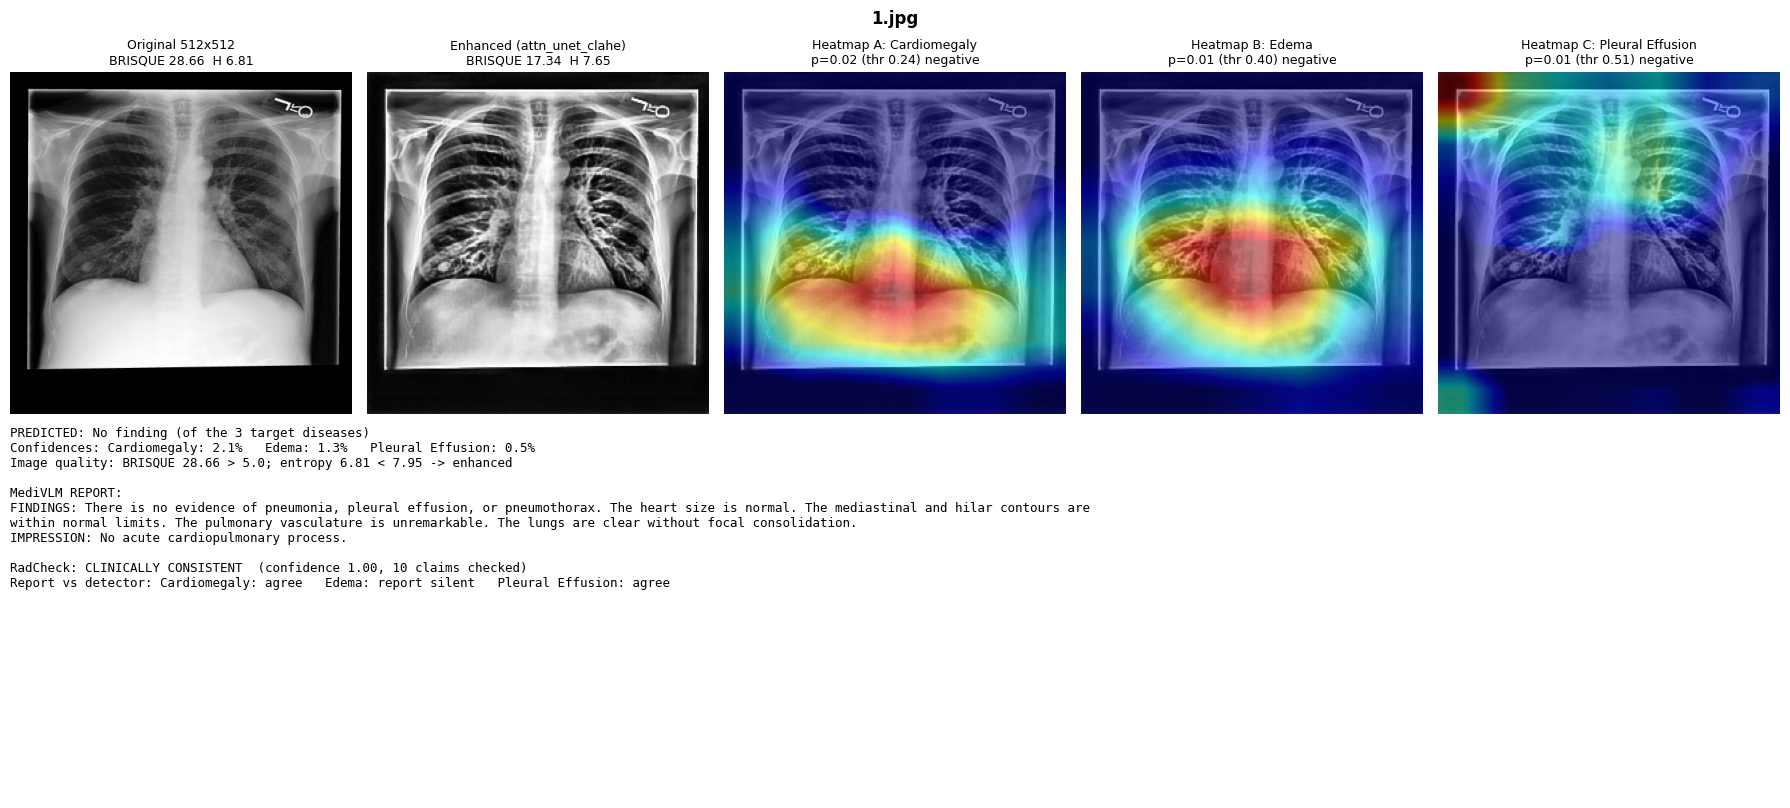

[1/1] 1.jpg done {'enhance_s': 0.3, 'detect_s': 0.2, 'scorecam_s': 40.3, 'report_s': 42.5} -> c:\Users\mohansai\OneDrive\Desktop\VLIL\Complete Pipeline\results\1


In [11]:
results = []
for i, name in enumerate(SAMPLE_IMAGES, 1):
    path = ROOT / name
    if not path.exists():
        print(f"skip (missing): {name}")
        continue
    print(f"[{i}/{len(SAMPLE_IMAGES)}] {name} ...", flush=True)
    results.append(run_pipeline(path))
    print(f"[{i}/{len(SAMPLE_IMAGES)}] {name} done {results[-1]['timing_s']} -> {RESULTS_DIR / path.stem}", flush=True)

## Summary

In [12]:
rows = []
for r in results:
    rc = r["radcheck"]
    rows.append({
        "image": Path(r["image_path"]).name,
        "enhancement": r["enhancement"]["method"],
        **{d: round(p, 3) for d, p in r["detection"]["probabilities"].items()},
        "predicted": r["detection"]["predicted_class"],
        "radcheck": ("unverified" if rc is None or "error" in rc else
                     "HALLUCINATED" + f" ({rc['overall_confidence']:.2f})" if rc["hallucination_detected"] else
                     "unverified (incomplete)" if rc.get("llm_errors") else
                     f"consistent ({rc['overall_confidence']:.2f})"),
        "report/CNN disagreements": sum(c["agreement"] == "DISAGREE" for c in r["consistency"].values()),
        "total_s": round(sum(r["timing_s"].values()), 1),
    })
summary = pd.DataFrame(rows)
RESULTS_DIR.mkdir(exist_ok=True)
summary.to_csv(RESULTS_DIR / "summary.csv", index=False)
print(f"Saved per-image results + summary.csv to {RESULTS_DIR}")
pd.set_option("display.max_colwidth", 60)
summary

Saved per-image results + summary.csv to c:\Users\mohansai\OneDrive\Desktop\VLIL\Complete Pipeline\results


,image,enhancement,Cardiomegaly,Edema,Pleural Effusion,predicted,radcheck,report/CNN disagreements,total_s
0,1.jpg,attn_unet_clahe,0.021,0.013,0.005,No finding (of the 3 target diseases),consistent (1.00),0,83.3
